# Fase 5 · ASSESS — Evaluación del modelo

**Objetivo:** evaluar la capacidad del modelo para clasificar posibles vulnerabilidades y determinar sus
limitaciones con datos y proyectos **no utilizados en el entrenamiento**.

1. Partición de **prueba** (15 %, grupos de origen nunca vistos): métricas, matriz de confusión, curvas.
2. Desempeño **por categoría OWASP** (multietiqueta: F1 micro, F1 macro y matrices por categoría).
3. Análisis de **falsos positivos y falsos negativos**.
4. **Sobreajuste** y generalización.
5. Pruebas funcionales de la herramienta sobre **proyectos de microservicios** reales no vistos y sobre
   fragmentos externos (`scripts/evaluar.py`).
6. **Contribución del modelo**: ablación frente a las reglas solas y comparación con Semgrep
   (`scripts/contribucion.py`).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE))
sys.path.insert(0, str(BASE / "notebooks"))
import estilo as E  # noqa: E402
from vulnminer.catalogo import nombre_categoria  # noqa: E402
from vulnminer.modelo import ModeloVulnminer, a_unidades  # noqa: E402

E.aplicar()
pd.set_option("display.max_colwidth", 70)
df = pd.read_csv(BASE / "datos" / "dataset.csv", keep_default_na=False)
te = df[df.particion == "prueba"].reset_index(drop=True)
modelo = ModeloVulnminer.cargar(BASE / "vulnminer" / "modelos" / "vulnminer.joblib")
metricas = json.loads((BASE / "resultados" / "metricas.json").read_text())
externa = json.loads((BASE / "resultados" / "evaluacion_externa.json").read_text())
print(f"Prueba: {len(te):,} unidades de {te.proyecto.nunique()} grupos de origen no vistos | vulnerables: {te.vulnerable.sum():,}")

Prueba: 2,200 unidades de 263 grupos de origen no vistos | vulnerables: 821


## 1. Detector en la partición de prueba

Las métricas de esta sección son las del **modelo base** (sección 4 del notebook 04). La última fila de la
tabla muestra la **decisión final** de la herramienta, que añade la etapa de combinación descrita en la
sección 7.

In [2]:
X = modelo.transformar(a_unidades(te))
p = modelo.probabilidad(X=X)
y = te.vulnerable.values
yp = (p >= modelo.umbral).astype(int)
m = metricas["detector"]["prueba"]
mv = metricas["detector"]["prueba_umbral_validacion"]
fila = lambda x: {"Umbral": x["umbral"], "Precisión": x["precision"], "Sensibilidad (recall)": x["recall"], "F1": x["f1"],  # noqa: E731
                  "Exactitud": x["accuracy"], "AUC-ROC": x["roc_auc"], "Precisión promedio (AP)": x["ap"],
                  "Tasa de falsos positivos": x["tasa_falsos_positivos"]}
mf = dict(metricas["combinacion"]["prueba"], umbral=f"{metricas['combinacion']['umbral_base_codigo']} / {metricas['combinacion']['umbral_combinado']}")
pd.DataFrame({"Modelo base (umbral operativo)": fila(m), "Modelo base (umbral de validación)": fila(mv),
              "Decisión final de la herramienta (con combinación)": fila(mf)}).T

,Umbral,Precisión,Sensibilidad (recall),F1,Exactitud,AUC-ROC,Precisión promedio (AP),Tasa de falsos positivos
Modelo base (umbral operativo),0.35,0.84398,0.836784,0.840367,0.881364,0.929259,0.872076,0.092096
Modelo base (umbral de validación),0.35,0.84398,0.836784,0.840367,0.881364,0.929259,0.872076,0.092096
Decisión final de la herramienta (con combinación),0.45 / 0.88,0.818297,0.784409,0.800995,0.854545,0.910759,0.826759,0.103698


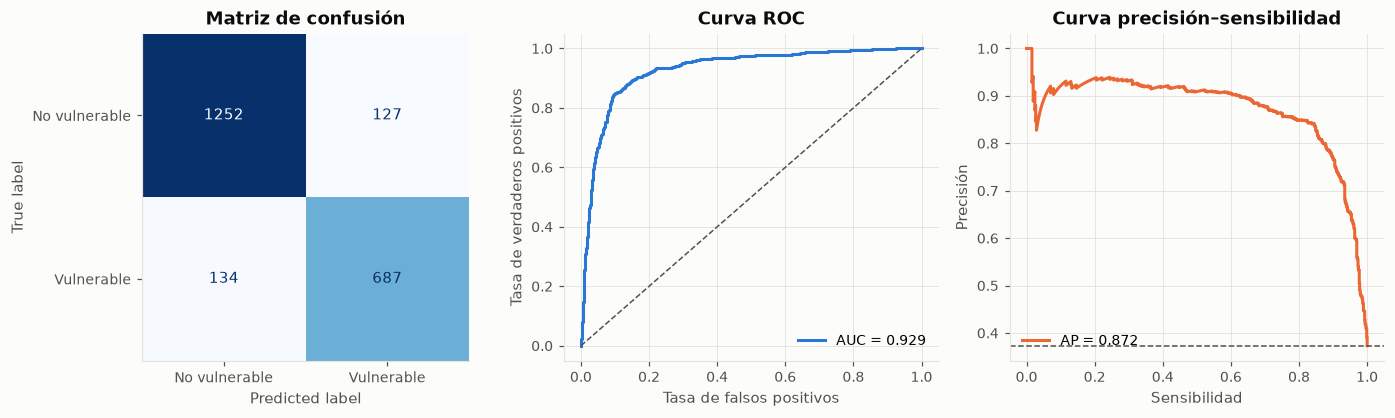

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
cm = confusion_matrix(y, yp)
ConfusionMatrixDisplay(cm, display_labels=["No vulnerable", "Vulnerable"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Matriz de confusión")
axes[0].grid(False)
fpr, tpr, _ = roc_curve(y, p)
axes[1].plot(fpr, tpr, color=E.AZUL, linewidth=2, label=f"AUC = {roc_auc_score(y, p):.3f}")
axes[1].plot([0, 1], [0, 1], color=E.TEXTO_2, linestyle="--", linewidth=1)
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curva ROC")
axes[1].legend(loc="lower right")
prec, rec, _ = precision_recall_curve(y, p)
axes[2].plot(rec, prec, color=E.NARANJA, linewidth=2, label=f"AP = {average_precision_score(y, p):.3f}")
axes[2].axhline(y.mean(), color=E.TEXTO_2, linestyle="--", linewidth=1)
axes[2].set_xlabel("Sensibilidad")
axes[2].set_ylabel("Precisión")
axes[2].set_title("Curva precisión–sensibilidad")
axes[2].legend(loc="lower left")
fig.tight_layout()
E.guardar(fig, "evaluacion_prueba")
plt.show()

### Desempeño por fuente, lenguaje y tipo de archivo

In [4]:
def tabla_grupo(clave):
    t = pd.DataFrame(metricas["detector"][clave]).T[["n", "vulnerables", "accuracy", "precision", "recall", "f1"]]
    return t.astype({"n": int, "vulnerables": int}).round(3).sort_values("n", ascending=False)

tabla_grupo("por_fuente")

,n,vulnerables,accuracy,precision,recall,f1
benigno,1023,0,0.984,0.000,0.000,0.000
codeql-tests,415,337,0.749,0.826,0.875,0.850
semgrep-rules,316,241,0.848,0.945,0.851,0.895
casos-controlados,187,95,0.759,0.868,0.621,0.724
owasp-benchmark-java,106,57,0.858,0.792,1.000,0.884
owasp-benchmark-python,70,30,0.929,0.931,0.900,0.915
kics,28,14,0.714,0.650,0.929,0.765
securityeval,23,23,0.826,1.000,0.826,0.905
juice-shop,22,17,0.455,0.778,0.412,0.538
vulnerableapp,10,7,0.600,0.714,0.714,0.714


In [5]:
pd.concat([tabla_grupo("por_lenguaje"), tabla_grupo("por_subtipo")])

,n,vulnerables,accuracy,precision,recall,f1
java,822,232,0.882,0.753,0.866,0.806
python,717,198,0.929,0.893,0.843,0.868
javascript,415,283,0.877,0.900,0.922,0.911
config,130,50,0.815,0.783,0.720,0.750
typescript,116,58,0.672,0.917,0.379,0.537
codigo,2070,771,0.886,0.848,0.844,0.846
compose,36,18,0.750,0.765,0.722,0.743
dockerfile,30,19,0.633,0.750,0.632,0.686
yaml,25,0,1.000,0.000,0.000,0.000
manifiesto,21,1,0.952,0.000,0.000,0.000


## 2. Desempeño por categoría OWASP

Dos vistas complementarias:

- **Extremo a extremo:** la unidad debe detectarse como vulnerable *y* recibir la categoría correcta. Es lo
  que experimenta el usuario de la herramienta.
- **Dado que es vulnerable:** calidad del categorizador por sí solo, sobre las unidades realmente vulnerables.

In [6]:
pc = pd.DataFrame(metricas["categorias"]["por_categoria"]).T
pc.insert(0, "categoria", [nombre_categoria(c) for c in pc.index])
cols = ["categoria", "ejemplos_entrenamiento", "soporte_prueba", "precision", "recall", "f1", "f1_dado_vulnerable"]
tabla_cat = pc[cols].copy()
for c in cols[3:]:
    tabla_cat[c] = tabla_cat[c].astype(float).round(3)
tabla_cat

,categoria,ejemplos_entrenamiento,soporte_prueba,precision,recall,f1,f1_dado_vulnerable
A01:2025,Pérdida de control de acceso,709,152,0.616,0.592,0.604,0.756
A02:2025,Configuración de seguridad incorrecta,263,58,0.388,0.448,0.416,0.567
A03:2025,Fallas en la cadena de suministro de software,33,13,0.375,0.462,0.414,0.788
A04:2025,Fallas criptográficas,500,117,0.783,0.769,0.776,0.853
A05:2025,Inyección,1335,289,0.738,0.830,0.782,0.862
A06:2025,Diseño inseguro,260,56,0.750,0.429,0.545,0.605
A07:2025,Fallas de autenticación,209,45,0.476,0.444,0.460,0.610
A08:2025,Fallas en la integridad del software o de los datos,154,77,0.808,0.273,0.408,0.455
A09:2025,"Fallas en el registro, alerta y monitoreo de seguridad",28,6,0.000,0.000,0.000,0.000
A10:2025,Manejo inadecuado de condiciones excepcionales,42,9,0.500,0.556,0.526,0.625


In [7]:
cm_ = metricas["categorias"]["prueba"]
pd.Series({"F1 micro (dado vulnerable)": cm_["f1_micro"], "F1 macro (dado vulnerable)": cm_["f1_macro"],
           "F1 micro (extremo a extremo)": cm_["f1_micro_extremo_a_extremo"],
           "F1 macro (extremo a extremo)": cm_["f1_macro_extremo_a_extremo"],
           "Hallazgos pendientes de revisión (sin categoría)": cm_["hallazgos_pendientes_de_revision"],
           "Exactitud del CWE (prueba)": metricas["cwe"]["exactitud_prueba"]}).round(3).to_frame("valor")

,valor
F1 micro (dado vulnerable),0.716
F1 macro (dado vulnerable),0.592
F1 micro (extremo a extremo),0.613
F1 macro (extremo a extremo),0.466
Hallazgos pendientes de revisión (sin categoría),77.000
Exactitud del CWE (prueba),0.676


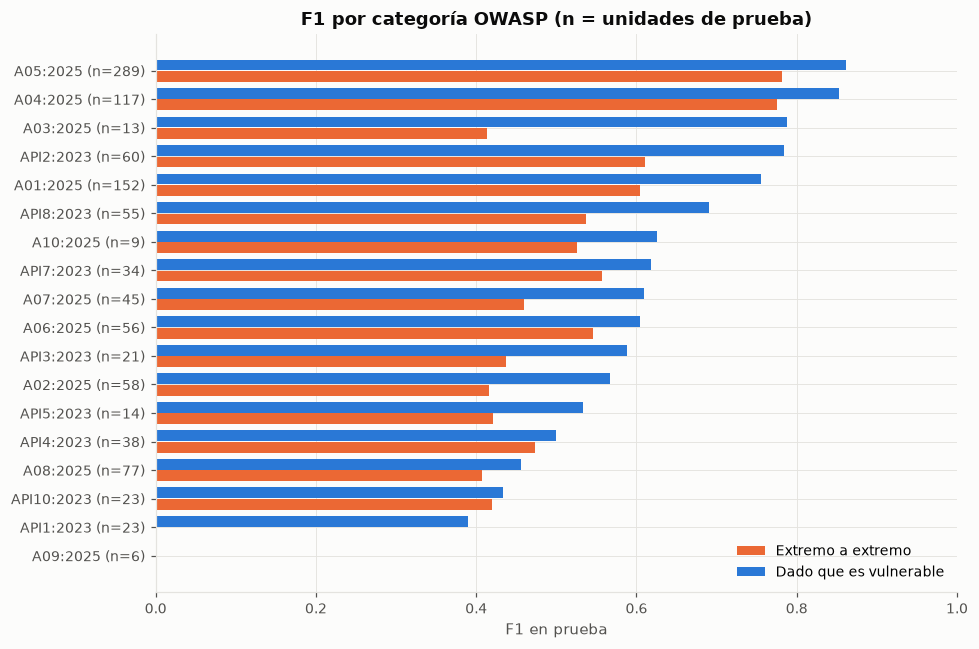

In [8]:
orden = pc.sort_values("f1_dado_vulnerable", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(orden))
ax.barh(yy + 0.2, orden["f1_dado_vulnerable"].astype(float), height=0.38, color=E.AZUL, label="Dado que es vulnerable")
ax.barh(yy - 0.2, orden["f1"].astype(float), height=0.38, color=E.NARANJA, label="Extremo a extremo")
ax.set_yticks(yy, [f"{c} (n={int(s)})" for c, s in zip(orden.index, orden.soporte_prueba)])
ax.set_xlim(0, 1)
ax.set_xlabel("F1 en prueba")
ax.set_title("F1 por categoría OWASP (n = unidades de prueba)")
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], loc="lower right")
fig.tight_layout()
E.guardar(fig, "evaluacion_categorias")
plt.show()

### Matrices de confusión por categoría (extremo a extremo)

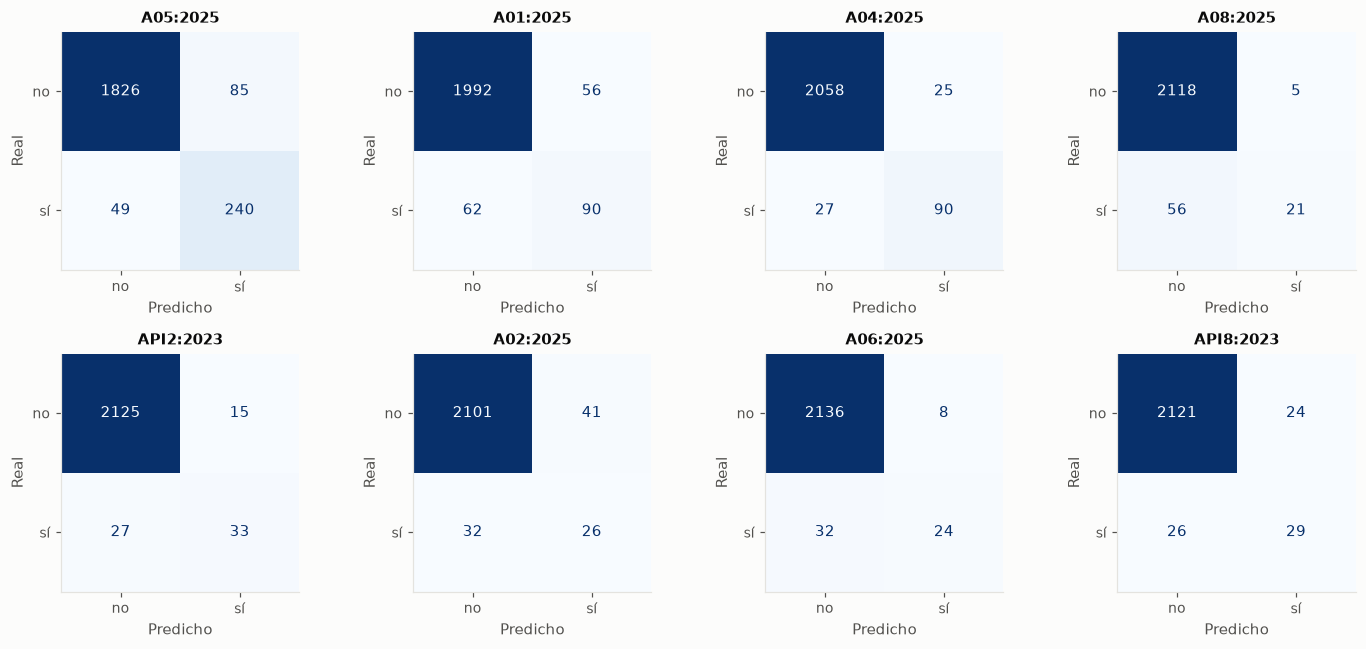

In [9]:
principales = [c for c in pc.sort_values("soporte_prueba", ascending=False).index[:8]]
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, c in zip(axes.ravel(), principales):
    mc = np.array(pc.loc[c, "matriz_confusion"])
    ConfusionMatrixDisplay(mc, display_labels=["no", "sí"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(c, fontsize=10)
    ax.grid(False)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
fig.tight_layout()
E.guardar(fig, "evaluacion_matrices_categoria")
plt.show()

## 3. Análisis de falsos positivos y falsos negativos

In [10]:
pred = pd.read_csv(BASE / "resultados" / "predicciones_prueba.csv", keep_default_na=False)
pred["error"] = np.where((pred.vulnerable == 1) & (pred.prediccion == 0), "falso negativo",
                         np.where((pred.vulnerable == 0) & (pred.prediccion == 1), "falso positivo", "acierto"))
errores = pd.crosstab(pred.fuente, pred.error)
errores

error,acierto,falso negativo,falso positivo
fuente,,,
benigno,1007,0,16
casos-controlados,142,36,9
codeql-tests,311,42,62
juice-shop,10,10,2
kics,20,1,7
owasp-benchmark-java,91,0,15
owasp-benchmark-python,65,3,2
securityeval,19,4,0
semgrep-rules,268,36,12


In [11]:
fn = pred[pred.error == "falso negativo"]
fn_cat = fn.owasp2025.str.split(";").explode().value_counts()
tot_cat = pred[pred.vulnerable == 1].owasp2025.str.split(";").explode().value_counts()
(fn_cat / tot_cat).dropna().sort_values(ascending=False).round(2).to_frame("tasa de falsos negativos por categoría")

,tasa de falsos negativos por categoría
owasp2025,
A03:2025,0.54
A07:2025,0.40
A01:2025,0.23
A10:2025,0.22
A02:2025,0.21
A08:2025,0.19
A04:2025,0.17
A05:2025,0.07
A06:2025,0.07


In [12]:
def mostrar(fila, n_lineas=14):
    reg = te[te.id == fila.id].iloc[0]
    u = a_unidades(te[te.id == fila.id])[0]
    u.lineas = list(range(reg.linea_inicio, reg.linea_inicio + len(reg.codigo.splitlines())))
    rel = modelo.lineas_relevantes(u)
    print(f"[{fila.error}] {fila.fuente} · {fila.archivo} · {fila.unidad} | P={fila.probabilidad:.3f} | "
          f"real: {fila.owasp2025 or 'no vulnerable'} {fila.cwe} | predicho: {fila.categorias_predichas or '-'}")
    print("líneas más influyentes:", [(l, round(c, 3)) for l, c in rel])
    print("\n".join(reg.codigo.splitlines()[:n_lineas]), "\n")

for _, f in pred[pred.error == "falso positivo"].sort_values("probabilidad", ascending=False).head(4).iterrows():
    mostrar(f)

[falso positivo] codeql-tests · java/ql/test/query-tests/security/CWE-502/A.java · deserialize8 | P=0.998 | real: no vulnerable  | predicho: A02:2025
líneas más influyentes: [(74, 0.015), (72, 0.01), (73, 0.002)]
  public void deserialize8(Socket sock) throws java.io.IOException {
    Kryo kryo = getSafeKryo();
    Input input = new Input(sock.getInputStream());
    Object o = kryo.readClassAndObject(input); // OK
  } 

[falso positivo] codeql-tests · java/ql/test/query-tests/security/CWE-502/A.java · deserializeWithSerialKiller | P=0.998 | real: no vulnerable  | predicho: A02:2025;A08:2025
líneas más influyentes: [(39, 0.049), (40, 0.023), (38, 0.002)]
  public Object deserializeWithSerialKiller(Socket sock) throws java.io.IOException, ClassNotFoundException {
    InputStream inputStream = sock.getInputStream();
    ObjectInputStream in = new SerialKiller(inputStream, "/etc/serialkiller.conf");
    return in.readUnshared(); // OK
  } 

[falso positivo] codeql-tests · java/ql/test/quer

In [13]:
for _, f in pred[pred.error == "falso negativo"].sort_values("probabilidad").head(4).iterrows():
    mostrar(f)

[falso negativo] juice-shop · registerAdminChallenge_1.ts · req | P=0.006 | real: A08:2025 CWE-915 | predicho: A01:2025
líneas más influyentes: [(34, 0.003), (37, 0.001), (35, 0.001)]
      resource.create.send.before((req: Request, res: Response, context: { instance: { id: any }, continue: any }) => {
        WalletModel.create({ UserId: context.instance.id }).catch((err: unknown) => {
          console.log(err)
        })
        context.instance.role = context.instance.role ? context.instance.role : 'customer'
        return context.continue
      }) 

[falso negativo] securityeval · CWE-306_pearce_1.py · decorated_function | P=0.010 | real: A07:2025 CWE-306 | predicho: -
líneas más influyentes: [(9, 0.002), (8, 0.001), (12, -0.001)]
    @wraps(f)
    def decorated_function(*args, **kws):
        if session['username'] is None:
            return redirect('/login')
        return f(*args, **kws) 

[falso negativo] semgrep-rules · dockerfile/security/php-version-usage.dockerfile · et

## 4. Sobreajuste y generalización

In [14]:
entreno = df[df.particion.isin(["entrenamiento", "validacion"])]
muestra = entreno.sample(min(3000, len(entreno)), random_state=1)
pe = modelo.probabilidad(a_unidades(muestra))
filas = {
    "Datos de ajuste (entren. + valid.)": [f1_score(muestra.vulnerable, pe >= modelo.umbral), roc_auc_score(muestra.vulnerable, pe)],
    "Prueba (grupos no vistos)": [m["f1"], m["roc_auc"]],
}
web = externa.get("fragmentos_web")
if web:
    filas["Fragmentos de foros y documentación"] = [web["f1"], web["roc_auc"]]
gen = pd.DataFrame(filas, index=["F1", "AUC-ROC"]).T.round(3)
gen

,F1,AUC-ROC
Datos de ajuste (entren. + valid.),0.939,0.996
Prueba (grupos no vistos),0.840,0.929
Fragmentos de foros y documentación,0.800,0.856


La diferencia entre los datos de ajuste y la prueba muestra el grado de sobreajuste. El modelo memoriza
parte de los ejemplos de entrenamiento (como cualquier modelo léxico de alta dimensión), pero conserva
un desempeño útil sobre proyectos y fuentes que nunca vio.

## 5. Prueba funcional sobre proyectos de microservicios no vistos

La herramienta completa (`vulnminer scan`) se ejecutó sobre cinco proyectos vulnerables con
vulnerabilidades documentadas (crAPI de OWASP, VAmPI, dvws-node, Damn Vulnerable RESTaurant y
VRPlayground) y sobre dos
proyectos de referencia sin vulnerabilidades intencionales (Spring PetClinic Microservices y Online
Boutique de Google). Una vulnerabilidad documentada se cuenta como **detectada** si algún hallazgo cae en
la función que la contiene.

In [15]:
proy = pd.DataFrame({k: {c: v[c] for c in ("tipo", "microservicios", "archivos", "unidades", "hallazgos",
                                            "hallazgos_por_100_unidades", "vulnerabilidades_documentadas", "detectadas",
                                            "sensibilidad", "categoria_correcta")}
                     for k, v in externa["proyectos"].items()}).T
proy

,tipo,microservicios,archivos,unidades,hallazgos,hallazgos_por_100_unidades,vulnerabilidades_documentadas,detectadas,sensibilidad,categoria_correcta
VAmPI,vulnerable,1,15,66,23,34.85,9,5,0.556,3
crAPI,vulnerable,7,268,1385,153,11.05,14,8,0.571,6
dvws-node,vulnerable,1,62,271,106,39.11,21,19,0.905,16
restaurant-api,vulnerable,1,61,170,18,10.59,6,1,0.167,1
VRPlayground,vulnerable,6,38,123,59,47.97,16,16,1.0,10
petclinic-microservices,referencia,9,77,229,7,3.06,0,0,None,0
microservices-demo,referencia,12,41,150,18,12.0,0,0,None,0
proyecto-demo,demostracion,4,19,65,17,26.15,19,13,0.684,13


In [16]:
r = externa["resumen_proyectos_vulnerables"]
print(f"Vulnerabilidades documentadas detectadas: {r['detectadas']}/{r['vulnerabilidades_documentadas']} "
      f"(sensibilidad {r['sensibilidad']:.2f}); con categoría correcta: {r['categoria_correcta']} "
      f"({r['categoria_correcta_sobre_detectadas']:.0%} de las detectadas)")
det = pd.DataFrame([d | {"proyecto": k} for k, v in externa["proyectos"].items() for d in v["detalle"]])
det[["proyecto", "id", "nombre", "detectada", "confianza", "categorias_esperadas", "categorias_predichas", "categoria_correcta"]]

Vulnerabilidades documentadas detectadas: 49/66 (sensibilidad 0.74); con categoría correcta: 36 (74% de las detectadas)


,proyecto,id,nombre,detectada,confianza,categorias_esperadas,categorias_predichas,categoria_correcta
0,VAmPI,VAMPI-01,Inyección SQL en la búsqueda de usuario,False,0.000,[A05:2025],[],False
1,VAmPI,VAMPI-02,Cambio de contraseña de otro usuario,True,0.961,"[A01:2025, API1:2023]","[A07:2025, API2:2023]",False
2,VAmPI,VAMPI-03,BOLA en la consulta de libros,False,0.000,"[A01:2025, API1:2023]",[],False
3,VAmPI,VAMPI-04,Asignación masiva del atributo admin en el registro,False,0.000,"[A08:2025, API3:2023]",[],False
4,VAmPI,VAMPI-05,Exposición excesiva de datos en el endpoint de depuración,False,0.000,"[A01:2025, API3:2023]",[],False
...,...,...,...,...,...,...,...,...
80,proyecto-demo,DEMO-15,BOLA: pedido de otro usuario por id,True,0.997,"[A01:2025, API1:2023]","[A01:2025, API1:2023]",True
81,proyecto-demo,DEMO-16,SSRF al importar un recibo desde una URL,True,0.896,"[A01:2025, API7:2023]",[A01:2025],True
82,proyecto-demo,DEMO-17,Deserialización insegura con pickle,True,0.991,[A08:2025],[A08:2025],True
83,proyecto-demo,DEMO-18,Dependencias sin versión fijada,True,0.427,[A03:2025],[A03:2025],True


In [17]:
porcat = pd.DataFrame(externa["por_categoria"]).T
porcat["sensibilidad"] = (porcat.detectadas / porcat.documentadas).round(2)
porcat["categoria_correcta_%"] = (porcat.categoria_correcta / porcat.documentadas * 100).round(0)
porcat.insert(0, "categoria", [nombre_categoria(c) for c in porcat.index])
porcat

,categoria,documentadas,detectadas,categoria_correcta,sensibilidad,categoria_correcta_%
A01:2025,Pérdida de control de acceso,21,10,8,0.48,38.0
A02:2025,Configuración de seguridad incorrecta,4,3,2,0.75,50.0
A04:2025,Fallas criptográficas,4,4,4,1.00,100.0
A05:2025,Inyección,19,18,12,0.95,63.0
A06:2025,Diseño inseguro,3,3,1,1.00,33.0
A07:2025,Fallas de autenticación,6,4,3,0.67,50.0
A08:2025,Fallas en la integridad del software o de los datos,9,7,5,0.78,56.0
API10:2023,Consumo inseguro de API,1,1,0,1.00,0.0
API1:2023,Autorización incorrecta a nivel de objeto,7,3,1,0.43,14.0
API2:2023,Autenticación incorrecta,10,8,6,0.80,60.0


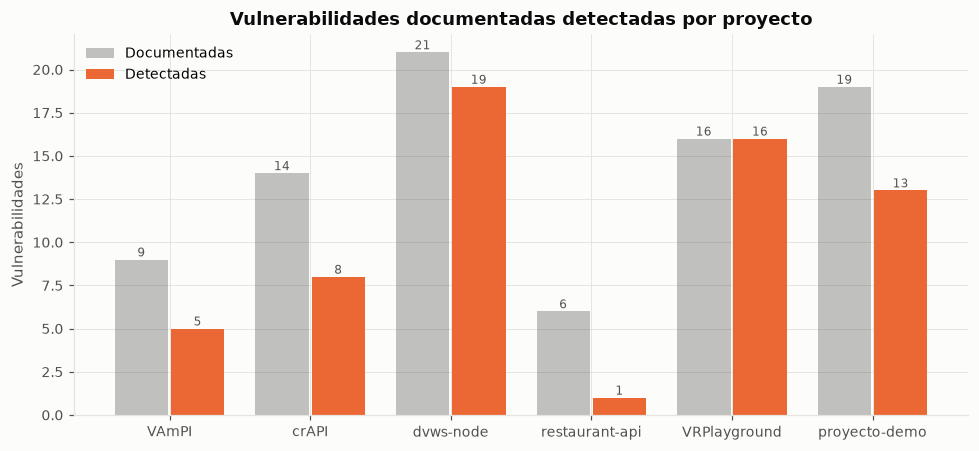

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
pv = proy[proy.tipo.isin(["vulnerable", "demostracion"])]
x = np.arange(len(pv))
b1 = ax.bar(x - 0.2, pv.vulnerabilidades_documentadas.astype(int), width=0.38, color=E.TEXTO_2, alpha=0.35, label="Documentadas")
b2 = ax.bar(x + 0.2, pv.detectadas.astype(int), width=0.38, color=E.NARANJA, label="Detectadas")
E.etiquetar_barras(ax, b1)
E.etiquetar_barras(ax, b2)
ax.set_xticks(x, pv.index)
ax.set_ylabel("Vulnerabilidades")
ax.set_title("Vulnerabilidades documentadas detectadas por proyecto")
ax.legend()
fig.tight_layout()
E.guardar(fig, "evaluacion_proyectos")
plt.show()

El proyecto de demostración (estructura del enunciado: gateway, NestJS, Spring Boot y FastAPI) lo escribí
para el laboratorio con vulnerabilidades sembradas; se informa aparte porque comparte autor con los casos
controlados y, por tanto, es una estimación optimista.

In [19]:
externa["resumen_proyecto_demo"]

{'vulnerabilidades_sembradas': 19, 'detectadas': 13, 'categoria_correcta': 13}

### Fragmentos externos

In [20]:
filas = []
for nombre, mm in (("Fragmentos de foros y documentación", web),):
    if mm:
        filas.append({"conjunto": nombre, "n": mm["n"], "vulnerables": mm["vulnerables"], "precision": mm["precision"],
                      "recall": mm["recall"], "f1": mm["f1"], "accuracy": mm["accuracy"], "auc": mm["roc_auc"]})
pd.DataFrame(filas).round(3)

,conjunto,n,vulnerables,precision,recall,f1,accuracy,auc
0,Fragmentos de foros y documentación,30,19,0.692,0.947,0.8,0.7,0.856


In [21]:
if web:
    w = pd.DataFrame(web["detalle"])
    w["acierto"] = w.vulnerable == w.prediccion
    display(w[["id", "tipo", "lenguaje", "vulnerable", "probabilidad", "prediccion", "acierto", "categorias", "owasp_esperado"]])

,id,tipo,lenguaje,vulnerable,probabilidad,prediccion,acierto,categorias,owasp_esperado
0,W02,Command Injection (Java),java,1,0.978,1,True,[A05:2025],A05:2025
1,W03,Eval / inyección de código (Node.js),javascript,1,0.915,1,True,[A05:2025],A05:2025
2,W04,Deserialización insegura (Python),python,1,0.999,1,True,[A08:2025],A08:2025
3,W05,Cross-Site Scripting (JavaScript),javascript,1,0.990,1,True,[A05:2025],A05:2025
4,W08,PreparedStatement (Java),java,0,0.224,0,True,[A05:2025],
5,W09,Ejecución sin shell (Python),python,0,0.367,0,True,[A05:2025],
6,W10,Escape HTML en Flask (Python),python,0,0.368,0,True,[A05:2025],
7,W11,Defensa de Path Traversal (Java),java,0,0.149,0,True,[A01:2025],
8,W12,Corrección de eval con parseInt (Node.js),javascript,0,0.805,1,False,"[A06:2025, API4:2023]",
9,W13,SQL Injection (Java),java,1,0.693,1,True,[A05:2025],A05:2025


## 6. Contribución del modelo de clasificación

El enunciado permite usar reglas o herramientas existentes **siempre que se evidencie la contribución del
modelo**. Para medirla hice dos experimentos (`scripts/contribucion.py`):

**a) Ablación.** Con el mismo algoritmo del detector final (SVM lineal calibrada, C = 1) y el mismo
protocolo (umbral de máximo F1 en validación y reentrenamiento con entrenamiento + validación) comparé:

- **Reglas solas**: sin aprendizaje; una unidad es vulnerable si activa al menos *k* indicadores de operación
  peligrosa. Uso dos versiones: *k* elegido en validación (mismo criterio que el umbral del modelo) y *k*
  calibrado en el conjunto de desarrollo con 5 % de falsas alarmas (mismo criterio que el umbral operativo).
- **Solo indicadores** de análisis estático con el clasificador (y con Random Forest, por si las variables
  necesitaran un modelo no lineal).
- **Solo texto**: TF-IDF de tokens y de caracteres.
- **Modelo completo**: texto + indicadores (el modelo base de la herramienta).
- **Modelo completo + combinación**: la decisión final de la herramienta (sección 7).

En los proyectos externos la comparación se hace a nivel de unidad: las 66 funciones con vulnerabilidades
documentadas frente a todas las unidades de los proyectos limpios (PetClinic y Online Boutique). Como cada
variante tiene su propio umbral, también informo la **sensibilidad con 5 % de falsas alarmas**, que compara
las variantes en el mismo punto de operación.

In [22]:
contrib = json.loads((BASE / "resultados" / "contribucion_modelo.json").read_text())
abl = pd.DataFrame(contrib["ablacion"]).set_index("variante")
tabla_abl = pd.DataFrame({
    "Variables": abl.variables, "Umbral": abl.umbral,
    "Prueba: precisión": abl.prueba_precision, "Prueba: sensibilidad": abl.prueba_recall, "Prueba: F1": abl.prueba_f1,
    "Prueba: AUC": abl.prueba_roc_auc,
    "Externo: detectadas": abl.ext_detectadas.astype(int).astype(str) + "/" + abl.ext_documentadas.astype(int).astype(str),
    "Externo: falsas alarmas": abl.ext_falsas_alarmas, "Externo: AUC": abl.ext_auc,
    "Externo: sensibilidad con 5 % FA": abl.ext_sensibilidad_con_5pct_falsas_alarmas,
    "Demo: detectadas": abl.ext_demo_detectadas.astype(int).astype(str) + "/" + abl.ext_demo_sembradas.astype(int).astype(str)})
tabla_abl.round(3)

,Variables,Umbral,Prueba: precisión,Prueba: sensibilidad,Prueba: F1,Prueba: AUC,Externo: detectadas,Externo: falsas alarmas,Externo: AUC,Externo: sensibilidad con 5 % FA,Demo: detectadas
variante,,,,,,,,,,,
"Reglas solas (indicadores, sin aprendizaje)",99,1,0.519,0.797,0.629,0.705,64/66,0.522,0.927,0.773,18/19
"Reglas solas, k calibrado en desarrollo",99,4,0.591,0.202,0.301,0.705,51/66,0.047,0.927,0.773,4/19
Solo indicadores de análisis estático,149,0.27,0.559,0.800,0.658,0.802,46/66,0.451,0.701,0.379,13/19
Solo indicadores con Random Forest,149,0.34,0.611,0.867,0.717,0.841,56/66,0.388,0.786,0.152,14/19
Solo texto (TF-IDF de tokens y caracteres),120000,0.33,0.807,0.820,0.813,0.922,40/66,0.063,0.847,0.545,11/19
Modelo completo (TF-IDF + indicadores),120149,0.35,0.844,0.837,0.840,0.929,38/66,0.084,0.838,0.515,13/19
Modelo completo + combinación (herramienta),120150,0.45/0.88,0.818,0.784,0.801,0.911,49/66,0.066,0.939,0.742,13/19


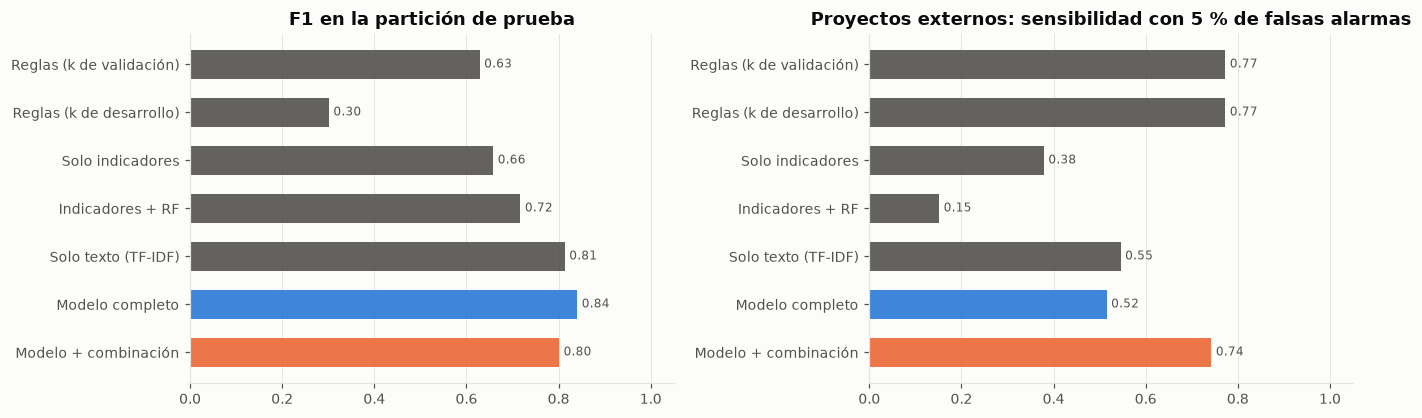

In [23]:
cortos = {"reglas": "Reglas (k de validación)", "reglas_desarrollo": "Reglas (k de desarrollo)",
          "indicadores": "Solo indicadores", "indicadores_rf": "Indicadores + RF", "tfidf": "Solo texto (TF-IDF)",
          "completo": "Modelo completo", "herramienta": "Modelo + combinación"}
a = pd.DataFrame(contrib["ablacion"]).set_index("clave").loc[list(cortos)]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
yy = np.arange(len(a))[::-1]
colores = [E.NARANJA if k == "herramienta" else E.AZUL if k == "completo" else E.TEXTO_2 for k in a.index]
for ax, col, titulo in ((axes[0], "prueba_f1", "F1 en la partición de prueba"),
                        (axes[1], "ext_sensibilidad_con_5pct_falsas_alarmas",
                         "Proyectos externos: sensibilidad con 5 % de falsas alarmas")):
    barras = ax.barh(yy, a[col].astype(float), color=colores, alpha=0.9, height=0.6)
    E.etiquetar_barras(ax, barras, "{:.2f}", horizontal=True)
    ax.set_yticks(yy, [cortos[k] for k in a.index])
    ax.set_xlim(0, 1.05)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
fig.tight_layout()
E.guardar(fig, "contribucion_ablacion")
plt.show()

**Lectura de la ablación.**

- En la partición de prueba, que mide si el modelo distingue un caso vulnerable de su versión corregida, el
  aprendizaje aporta mucho: las reglas y los indicadores solos quedan muy por debajo del texto y del modelo
  completo.
- En los proyectos reales ocurre algo distinto. Con *k* calibrado en desarrollo, las reglas solas detectan
  más vulnerabilidades que el modelo base con una tasa de falsas alarmas parecida. La razón es un **cambio de
  distribución**: en los datos de entrenamiento la versión vulnerable y la segura de un caso tienen casi las
  mismas operaciones peligrosas, por lo que el modelo aprendió a no dar peso a la *cantidad* de evidencia;
  en las aplicaciones reales, las funciones vulnerables suelen acumular varias operaciones peligrosas.

Este resultado motivó una iteración Assess → Modify/Model: la etapa de combinación de la sección 7.

**b) Comparación con Semgrep.** Semgrep es un analizador estático por reglas muy usado. Lo ejecuté con las
reglas comunitarias de su repositorio (`semgrep-rules`, las mismas cuyos casos de prueba forman parte del
dataset) sobre los mismos proyectos y con el mismo criterio de acierto: un hallazgo dentro de la función
documentada. En los proyectos limpios cuento las unidades de análisis que contienen algún hallazgo.

In [24]:
sg = contrib["semgrep"]
comp_sg = pd.DataFrame(sg["proyectos"]).set_index("proyecto")
vul = comp_sg[comp_sg.tipo != "referencia"][["documentadas", "semgrep_detectadas", "vulnminer_detectadas",
                                             "semgrep_hallazgos", "vulnminer_hallazgos"]].astype(int)
ref = comp_sg[comp_sg.tipo == "referencia"][["unidades", "semgrep_unidades_marcadas", "vulnminer_unidades_marcadas",
                                             "semgrep_hallazgos", "vulnminer_hallazgos"]].astype(int)
print(f"Semgrep {sg['version']} — reglas: {sg['reglas']}")
display(vul)
display(ref)
pd.Series(sg["resumen"]).to_frame("total")

Semgrep 1.186.0 — reglas: semgrep-rules (python, java, javascript, typescript, dockerfile, yaml, generic, json)


,documentadas,semgrep_detectadas,vulnminer_detectadas,semgrep_hallazgos,vulnminer_hallazgos
proyecto,,,,,
VAmPI,9,1,5,17,23
crAPI,14,2,8,257,153
dvws-node,21,11,19,104,106
restaurant-api,6,2,1,26,18
VRPlayground,16,11,16,58,59
proyecto-demo,19,8,13,18,17


,unidades,semgrep_unidades_marcadas,vulnminer_unidades_marcadas,semgrep_hallazgos,vulnminer_hallazgos
proyecto,,,,,
petclinic-microservices,229,4,7,28,7
microservices-demo,150,39,18,80,18


,total
documentadas,66
semgrep_detectadas,27
vulnminer_detectadas,49
solo_vulnminer,23
solo_semgrep,1
ambas,26
union,50
unidades_limpias,379
semgrep_unidades_limpias_marcadas,43
vulnminer_unidades_limpias_marcadas,25


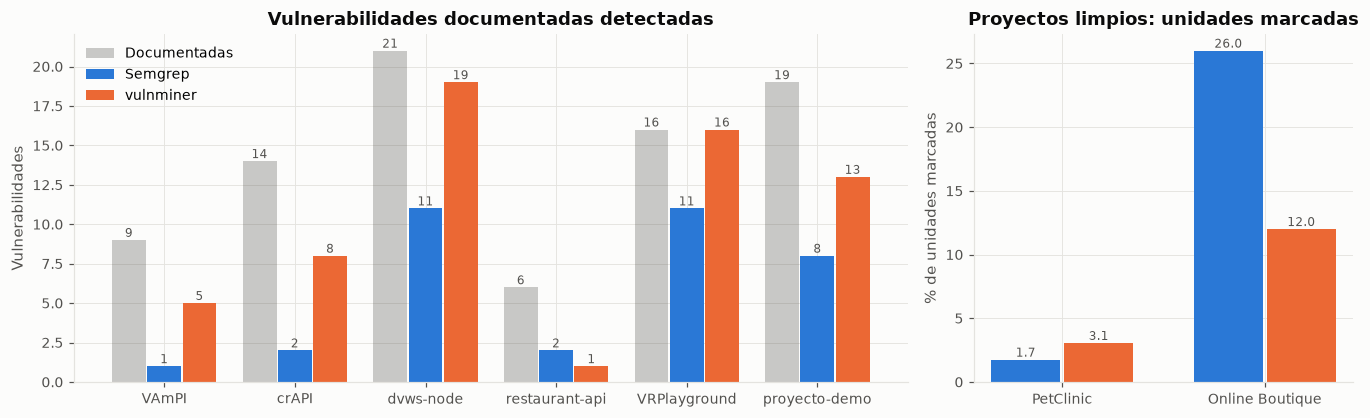

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [2.2, 1]})
x = np.arange(len(vul))
b0 = axes[0].bar(x - 0.27, vul.documentadas, width=0.26, color=E.TEXTO_2, alpha=0.3, label="Documentadas")
b1 = axes[0].bar(x, vul.semgrep_detectadas, width=0.26, color=E.AZUL, label="Semgrep")
b2 = axes[0].bar(x + 0.27, vul.vulnminer_detectadas, width=0.26, color=E.NARANJA, label="vulnminer")
for b in (b0, b1, b2):
    E.etiquetar_barras(axes[0], b)
axes[0].set_xticks(x, vul.index)
axes[0].set_ylabel("Vulnerabilidades")
axes[0].set_title("Vulnerabilidades documentadas detectadas")
axes[0].legend()
xr = np.arange(len(ref))
t1 = axes[1].bar(xr - 0.18, 100 * ref.semgrep_unidades_marcadas / ref.unidades, width=0.34, color=E.AZUL, label="Semgrep")
t2 = axes[1].bar(xr + 0.18, 100 * ref.vulnminer_unidades_marcadas / ref.unidades, width=0.34, color=E.NARANJA, label="vulnminer")
for b in (t1, t2):
    E.etiquetar_barras(axes[1], b, "{:.1f}")
axes[1].set_xticks(xr, ["PetClinic", "Online Boutique"])
axes[1].set_ylabel("% de unidades marcadas")
axes[1].set_title("Proyectos limpios: unidades marcadas")
fig.tight_layout()
E.guardar(fig, "contribucion_semgrep")
plt.show()

In [26]:
det_sg = pd.DataFrame(sg["detalle"])
det_sg["resultado"] = np.select([det_sg.semgrep & det_sg.vulnminer, det_sg.vulnminer, det_sg.semgrep],
                                ["ambas", "solo vulnminer", "solo Semgrep"], "ninguna")
display(pd.crosstab(det_sg.proyecto, det_sg.resultado))
det_sg[det_sg.resultado.isin(["solo vulnminer", "solo Semgrep"])][["proyecto", "id", "nombre", "categorias", "resultado", "reglas_semgrep"]]

resultado,ambas,ninguna,solo Semgrep,solo vulnminer
proyecto,,,,
VAmPI,1,4,0,4
VRPlayground,11,0,0,5
crAPI,2,6,0,6
dvws-node,11,2,0,8
proyecto-demo,7,5,1,6
restaurant-api,1,4,1,0


,proyecto,id,nombre,categorias,resultado,reglas_semgrep
1,VAmPI,VAMPI-02,Cambio de contraseña de otro usuario,"[A01:2025, API1:2023]",solo vulnminer,[]
5,VAmPI,VAMPI-06,Enumeración de usuarios y contraseñas en el login,"[A07:2025, API2:2023]",solo vulnminer,[]
6,VAmPI,VAMPI-07,ReDoS en la actualización del correo,"[A06:2025, API4:2023]",solo vulnminer,[]
7,VAmPI,VAMPI-08,Login sin limitación de intentos,"[A07:2025, API2:2023, API4:2023]",solo vulnminer,[]
10,crAPI,CRAPI-02,Asignación masiva del estado del pedido (reembolso),"[A08:2025, API3:2023]",solo vulnminer,[]
12,crAPI,CRAPI-04,SSRF y repeticiones ilimitadas en contactar mecánico,"[A01:2025, API4:2023, API7:2023]",solo vulnminer,[]
18,crAPI,CRAPI-10,Asignación masiva de parámetros de conversión del video,"[A08:2025, API3:2023]",solo vulnminer,[]
19,crAPI,CRAPI-11,Validación del JWT acepta algoritmos inseguros,"[A04:2025, API2:2023]",solo vulnminer,[]
20,crAPI,CRAPI-12,Clave del JWT obtenida de la URL jku del propio token,"[A04:2025, API2:2023]",solo vulnminer,[]
21,crAPI,CRAPI-13,Lectura del usuario del JWT sin verificar la firma,"[A04:2025, API2:2023]",solo vulnminer,[]


## 7. Iteración: etapa de combinación con la evidencia estática

Con el conjunto de **desarrollo** (aplicaciones reales, separado del entrenamiento y de la evaluación) ajusté
una regresión logística de dos variables: el logit de la probabilidad del modelo base y el número de
indicadores de operación peligrosa activos (`scripts/combinar.py`). Se aplica solo al código de servidor,
porque el conjunto de desarrollo no tiene vulnerabilidades de configuración ni de frontend.

En el código, una unidad es vulnerable si el modelo base está seguro (*p* ≥ u_base) **o** la probabilidad
combinada supera u_comb. Los umbrales se eligieron con predicciones fuera de pliegue (validación cruzada de
5 pliegues) manteniendo 5 % de falsas alarmas: la mayor sensibilidad y, dentro de una tolerancia de una
vulnerabilidad, la opción que más respeta al modelo base.

In [27]:
comb = metricas["combinacion"]
sel = pd.read_csv(BASE / "resultados" / "seleccion_combinacion.csv")
print("Coeficientes:", comb["coeficientes"], "| intercepto:", round(comb["intercepto"], 3))
print(f"Modelo base solo en desarrollo: sensibilidad {comb['desarrollo_modelo_base']['sensibilidad']:.2f}, "
      f"falsas alarmas {comb['desarrollo_modelo_base']['falsas_alarmas']:.3f}")
sel.round(3)

Coeficientes: {'logit_probabilidad': 0.707, 'evidencia_estatica': 0.921} | intercepto: -1.07
Modelo base solo en desarrollo: sensibilidad 0.72, falsas alarmas 0.050


,umbral_base_codigo,umbral_combinado,sensibilidad,falsas_alarmas,elegida
0,0.40,0.98,0.750,0.050,False
1,0.45,0.88,0.806,0.050,True
2,0.50,0.85,0.806,0.050,False
3,0.55,0.81,0.806,0.049,False
4,0.60,0.80,0.806,0.050,False
5,0.65,0.73,0.833,0.050,False
6,0.70,0.70,0.833,0.050,False
7,0.75,0.70,0.833,0.050,False
8,0.80,0.70,0.833,0.050,False


In [28]:
efecto = pd.DataFrame({
    "Prueba: F1": [m["f1"], comb["prueba"]["f1"]],
    "Prueba: precisión": [m["precision"], comb["prueba"]["precision"]],
    "Prueba: sensibilidad": [m["recall"], comb["prueba"]["recall"]],
    "Desarrollo: sensibilidad con 5 % FA": [comb["desarrollo_modelo_base"]["sensibilidad"],
                                            comb["desarrollo_fuera_de_pliegue"]["sensibilidad"]],
    "Externo (unidad): detectadas": [abl.loc["Modelo completo (TF-IDF + indicadores)", "ext_detectadas"],
                                     abl.loc["Modelo completo + combinación (herramienta)", "ext_detectadas"]],
    "Externo (unidad): falsas alarmas": [abl.loc["Modelo completo (TF-IDF + indicadores)", "ext_falsas_alarmas"],
                                         abl.loc["Modelo completo + combinación (herramienta)", "ext_falsas_alarmas"]],
}, index=["Modelo base", "Modelo base + combinación"])
efecto.round(3)

,Prueba: F1,Prueba: precisión,Prueba: sensibilidad,Desarrollo: sensibilidad con 5 % FA,Externo (unidad): detectadas,Externo (unidad): falsas alarmas
Modelo base,0.840,0.844,0.837,0.722,38,0.084
Modelo base + combinación,0.801,0.818,0.784,0.806,49,0.066


La combinación sacrifica algo de F1 en la partición de prueba (casos de pruebas de reglas casi idénticos entre
sí) a cambio de una mejora clara en aplicaciones reales, que es el uso previsto de la herramienta. Los
resultados de la sección 5 ya corresponden a la herramienta con la combinación. Como los proyectos externos
se habían usado antes en los diagnósticos, esas cifras deben leerse como una estimación algo optimista.